# Упражнения по Boosting and Stacking 

![Boosting.png](Assets/Boosting.png)

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

Мы будем использовать базу данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированную на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [13]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

from sklearnex import patch_sklearn
patch_sklearn()

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и проанализируйте структуру и типы данных. Типов данных будет слишком много, чтобы перечислять их по каждому столбцу отдельно. Вместо этого сгруппируйте типы по количеству.
* Определите, требуется ли масштабирование столбцов с числами типа float.

In [14]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

В наборе данных довольно много столбцов с предикторами.

И все они — значения типа float. Единственное значение, не относящееся к типу float, — это столбец «categories», который и является объектом прогнозирования.

Минимальное и максимальное значения для столбцов типа float составляют -1,0 и 1,0 соответственно. Однако для методов, основанных на дереве, масштабирование никогда не требуется.

In [15]:
# Структура данных: количество строк и столбцов
data.shape

(10299, 562)

In [16]:
# Типы данных, сгруппированные по количеству
data.dtypes.value_counts()

float64    561
object       1
Name: count, dtype: int64

In [17]:
# Минимальные и максимальные значения столбцов типа float — нужно ли масштабирование
float_columns = (data.dtypes == float)

print(data.loc[:, float_columns].min().value_counts())
print(data.loc[:, float_columns].max().value_counts())

-1.0    561
Name: count, dtype: int64
1.0    561
Name: count, dtype: int64


## Вопрос 2

* Присвойте действиям целочисленные коды.
* Разделите данные на обучающий и тестовый наборы. Решите, будет ли производиться стратификация данных при разделении на обучающий и тестовый наборы или нет.

**ПРИМЕЧАНИЕ**: Мы собираемся создать обучающий и тестовый наборы данных из `data`. На этих наборах данных мы будем проводить поиск по сетке с различными значениями параметров. Это может занять некоторое время. Чтобы сократить время поиска по сетке, вы можете уменьшить разрешение `data` и создать `X_train, X_test, y_train, y_test` на основе набора данных с уменьшенным разрешением.

Теперь разделите данные на обучающий и тестовый наборы. Здесь не использовалось стратифицированное деление. Если возникнут проблемы с какими-либо метриками ошибок на тестовом наборе, может быть целесообразно начать подбор модели с использованием стратифицированного деления. Однако метод бустинга является довольно мощной моделью, поэтому в данном случае это может оказаться ненужным.

In [18]:
# Присвоение действиям целочисленных кодов
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])

data['Activity'].value_counts()

Activity
0    1944
2    1906
1    1777
3    1722
5    1544
4    1406
Name: count, dtype: int64

In [19]:
# Разделение данных на обучающий и тестовый наборы (без стратификации)
feature_columns = [x for x in data.columns if x != 'Activity']

X_train, X_test, y_train, y_test = train_test_split(data[feature_columns], data['Activity'],
                                                    test_size=0.3, random_state=42)

## Вопрос 3

* Постройте модели градиентного бустинга с деревьями, установив все параметры по умолчанию, для следующих значений количества деревьев (`n_estimators = [25, 50, 100, 200, 400]`) и оцените точность на тестовых данных для каждой из этих моделей.
* Постройте график зависимости точности от количества оценок.

**Примечание:** Выполнение этого задания может занять некоторое время в зависимости от количества различных значений, подбираемых для оценок. Установка параметра `max_features=4` в классификаторе градиентного бустинга увеличит скорость сходимости.

Кроме того, это задание аналогично заданию 3 из 9-й недели, за исключением того, что для моделей с бустингом не существует такого понятия, как «ошибка out-of-bag». Кроме того, в модели градиентного бустинга присутствует ошибка в настройке `warm_flag=True`, поэтому не используйте её. Просто создайте модель внутри цикла `for` и задайте количество оценок в этот момент. Это приведёт к тому, что подбор модели займёт немного больше времени. Кроме того, подбор моделей бустинга, как правило, занимает больше времени, чем подбор моделей методом bagging, поскольку «решающие пеньки» необходимо подбирать последовательно.

Теперь построим график результата.

In [20]:
# Модели градиентного бустинга с разным количеством деревьев и точность на тестовых данных
error_list = []

tree_list = [25, 50, 100, 200, 400]
for n_trees in tree_list:
    GBC = GradientBoostingClassifier(n_estimators=n_trees, max_features=4, random_state=42)
    GBC.fit(X_train.values, y_train.values)
    y_pred = GBC.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    error_list.append({'n_trees': n_trees, 'accuracy': accuracy})

error_df = pd.DataFrame(error_list).set_index('n_trees')
error_df

c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X 

,accuracy
n_trees,
25,0.931068
50,0.959547
100,0.976375
200,0.984142
400,0.986731


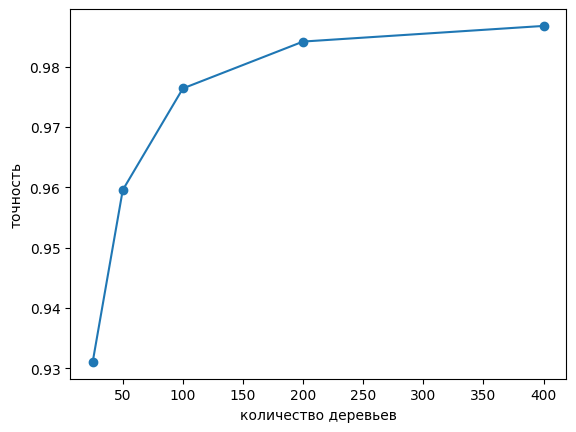

In [21]:
# График зависимости точности от количества оценок
import matplotlib.pyplot as plt

ax = error_df.plot(legend=False, marker='o')
ax.set(xlabel='количество деревьев', ylabel='точность')
plt.show()

## Вопрос 4

* Используя поиск по сетке с перекрестной валидацией, постройте новый классификатор с градиентным бустингом, используя список оценок, аналогично вопросу 3. Также рассмотрите возможность изменения скоростей обучения (0,1; 0,01; 0,001 и т. д.), значения подвыборки (1,0 или 0,5) и количества максимальных признаков (1, 2 и т. д.).
* Проанализируйте параметры модели с наилучшей подгонкой.
* Рассчитайте соответствующие метрики ошибок для этой модели и проанализируйте матрицу путаницы.

**Примечание:** выполнение этого вопроса может занять некоторое время в зависимости от количества признаков, используемых в поиске по сетке. Рекомендуется начать с небольшого количества, чтобы убедиться в корректной работе, а затем добавить больше признаков. Установка параметра `max_features=4` в классификаторе с градиентным бустингом увеличит скорость сходимости.

Показатели ошибок. Отчет о классификации особенно удобен в случаях с несколькими классами.

Матрица путаницы. Обратите внимание, что модель с градиентным бустингом испытывает небольшие затруднения при различении классов активности 1 и 2.

In [22]:
# Поиск по сетке с перекрестной валидацией для градиентного бустинга
param_grid = {'n_estimators': tree_list,
              'learning_rate': [0.1, 0.01],
              'subsample': [1.0, 0.5],
              'max_features': [2, 4]}

GV_GBC = GridSearchCV(GradientBoostingClassifier(random_state=42),
                      param_grid=param_grid,
                      scoring='accuracy',
                      cv=3,
                      n_jobs=-1)

GV_GBC = GV_GBC.fit(X_train, y_train)

# Параметры модели с наилучшей подгонкой
GV_GBC.best_estimator_

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",400
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

In [23]:
# Показатели ошибок для лучшей модели
y_pred = GV_GBC.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.97      0.97      0.97       563
           2       0.97      0.97      0.97       547
           3       1.00      1.00      1.00       539
           4       1.00      1.00      1.00       420
           5       0.99      1.00      0.99       424

    accuracy                           0.99      3090
   macro avg       0.99      0.99      0.99      3090
weighted avg       0.99      0.99      0.99      3090



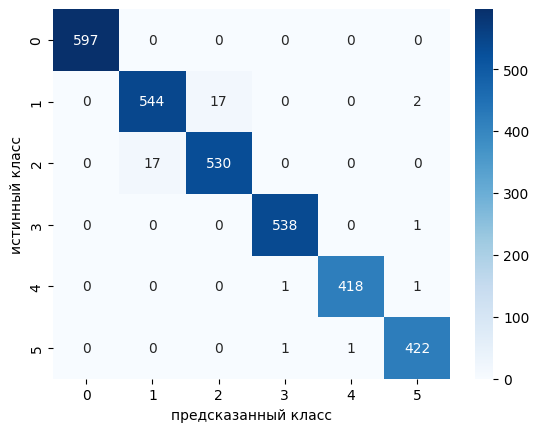

In [24]:
# Матрица путаницы
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='предсказанный класс', ylabel='истинный класс')
plt.show()

## Вопрос 5

* Создайте модель AdaBoost и подстройте её с помощью поиска по сетке, аналогично вопросу 4. Попробуйте использовать различные значения оценщика в диапазоне от 100 до 200.
* Сравните погрешности модели AdaBoost с погрешностями модели GradientBoostedClassifier.

**ПРИМЕЧАНИЕ:** Установка параметра `max_features=4` в классификаторе на основе дерева решений, используемом в качестве базового классификатора для AdaBoost, повысит скорость сходимости.

Лучшая модель.

Показатели ошибок. Обратите внимание, что проблемы с классами 1 и 2, по-видимому, усугубились и теперь затрагивают также класс 0. Также обратите внимание на другие проблемы, связанные с классами 3–5. Алгоритм AdaBoost очень чувствителен к выбросам, поэтому именно в этом может заключаться причина проблемы.

In [27]:
# Модель AdaBoost и поиск по сетке
ABC = AdaBoostClassifier(DecisionTreeClassifier(max_features=4), random_state=42)

param_grid = {'n_estimators': [100, 150, 200],
              'learning_rate': [0.01, 0.001]}

GV_ABC = GridSearchCV(ABC,
                      param_grid=param_grid,
                      scoring='accuracy',
                      cv=3,
                      n_jobs=-1)

GV_ABC = GV_ABC.fit(X_train, y_train)

In [26]:
# Лучшая модель AdaBoost
GV_ABC.best_estimator_

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ax_features=4)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.01
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",4


              precision    recall  f1-score   support

           0       0.81      0.80      0.81       597
           1       0.66      0.65      0.65       563
           2       0.68      0.69      0.69       547
           3       0.88      0.87      0.87       539
           4       0.83      0.84      0.84       420
           5       0.84      0.84      0.84       424

    accuracy                           0.78      3090
   macro avg       0.78      0.78      0.78      3090
weighted avg       0.78      0.78      0.78      3090



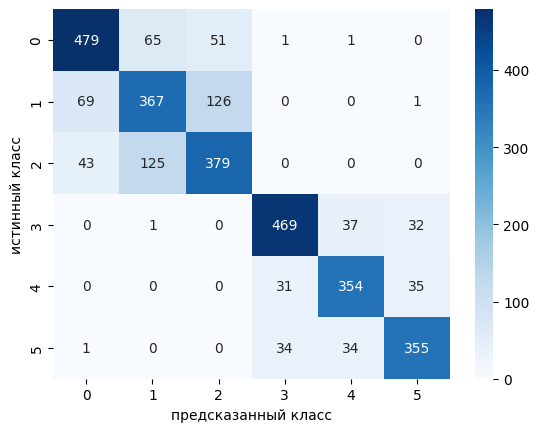

In [28]:
# Показатели ошибок и матрица путаницы AdaBoost для сравнения с градиентным бустингом
y_pred = GV_ABC.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='предсказанный класс', ylabel='истинный класс')
plt.show()

## Вопрос 6

* Постройте модель логистической регрессии с регуляризацией. Это может быть аналог модели, которая хорошо себя показала в упражнениях 4-й недели.
* Используя `VotingClassifier`, постройте модель логистической регрессии вместе с моделью GratientBoostedClassifier или AdaBoost (или обеими) из вопросов 4 и 5.
* Определите ошибку, как и ранее, и сравните результаты с соответствующими моделями с градиентным бустингом.
* Постройте матрицу путаницы для лучшей модели, созданной в этом наборе упражнений.

Проверьте ошибки и матрицу путаницы для модели логистической регрессии.

А теперь — многоуровневая модель (stacked model).

Наконец, рассмотрим ошибку классификатора при голосовании. Здесь мы показываем немного лучшие результаты, чем при использовании либо логистической регрессии, либо градиентных бустеров по отдельности. Однако тот факт, что логистическая регрессия демонстрирует почти такие же результаты, как и градиентные бустеры, служит важным напоминанием о том, что сначала следует пробовать самую простую модель. В некоторых случаях её эффективности будет вполне достаточно.

In [29]:
# Модель логистической регрессии с регуляризацией
LR_L2 = LogisticRegressionCV(Cs=5, cv=4, penalty='l2', max_iter=1000, n_jobs=-1)
LR_L2 = LR_L2.fit(X_train, y_train)

c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1811: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' instead. Use l1_ratios=(0,) instead of penalty='l2'  and l1_ratios=(1,) instead of penalty='l1'.
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.96      0.94      0.95       563
           2       0.95      0.96      0.95       547
           3       0.99      1.00      0.99       539
           4       1.00      0.99      0.99       420
           5       0.98      1.00      0.99       424

    accuracy                           0.98      3090
   macro avg       0.98      0.98      0.98      3090
weighted avg       0.98      0.98      0.98      3090



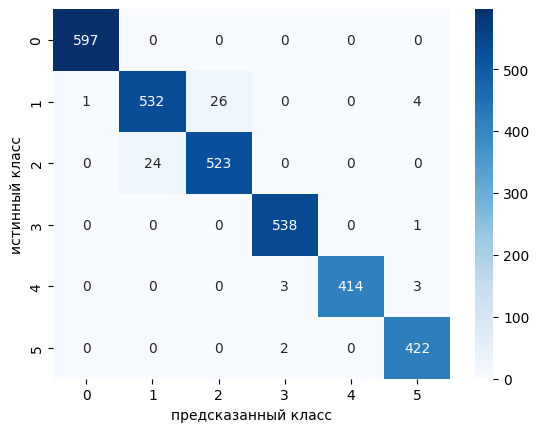

In [30]:
# Показатели ошибок и матрица путаницы логистической регрессии
y_pred = LR_L2.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='предсказанный класс', ylabel='истинный класс')
plt.show()

In [31]:
# VotingClassifier: логистическая регрессия + градиентный бустинг
estimators = [('LR_L2', LR_L2), ('GBC', GV_GBC.best_estimator_)]

VC = VotingClassifier(estimators, voting='hard')
VC = VC.fit(X_train, y_train)

c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1811: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' instead. Use l1_ratios=(0,) instead of penalty='l2'  and l1_ratios=(1,) instead of penalty='l1'.
  warnings.warn(
c:\Users\MVP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       597
           1       0.94      0.97      0.96       563
           2       0.98      0.94      0.96       547
           3       0.99      1.00      0.99       539
           4       1.00      0.99      0.99       420
           5       0.99      0.99      0.99       424

    accuracy                           0.98      3090
   macro avg       0.98      0.98      0.98      3090
weighted avg       0.98      0.98      0.98      3090



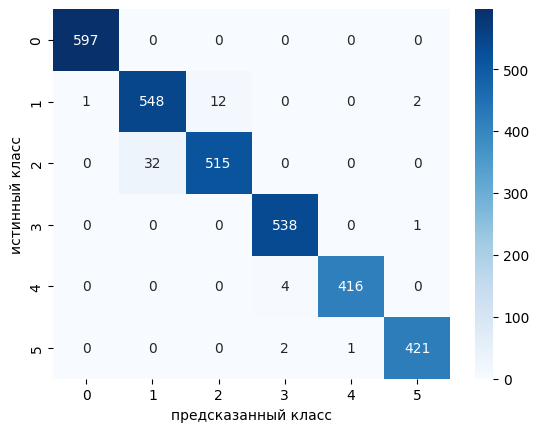

In [32]:
# Показатели ошибок и матрица путаницы лучшей модели (VotingClassifier)
y_pred = VC.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='предсказанный класс', ylabel='истинный класс')
plt.show()